# IPL 2008 to 2024: Is It Real, and Can We Predict It?

The [first notebook](ipl_analysis.ipynb) described what happened in the IPL: scores rose, the toss looked
like a coin flip, and CSK looked strong at Chepauk. Those were percentages with no measure of uncertainty.

This notebook asks two harder questions:

1. **Inference.** Which of those findings are statistically real, and which could be noise?
2. **Prediction.** Using only information available *before* a match, how well can we predict the winner,
   and does a model actually beat simple baselines?

**Approach in brief:** hypothesis tests with confidence intervals and a multiple-testing correction, then a
win-prediction model evaluated with a time-based split (train on the past, test on the future) so that
nothing from the future leaks into training.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
NAVY, ORANGE, GREY = "#1d2b64", "#e4572e", "#8a93b5"
SEED = 42
rng = np.random.default_rng(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)

def clean_strings(df):
    df.columns = df.columns.str.strip()
    for c in df.columns:
        if pd.api.types.is_string_dtype(df[c]):
            df[c] = df[c].str.strip()
    return df

matches = clean_strings(pd.read_csv("data/matches_2008-2024.csv")).rename(columns={"id": "match_id"})
balls = clean_strings(pd.read_csv("data/deliveries_2008-2024.csv.gz"))

# Same cleaning as the first notebook: renamed franchises are merged into one team
TEAM_FIX = {
    "Delhi Daredevils": "Delhi Capitals",
    "Kings XI Punjab": "Punjab Kings",
    "Royal Challengers Bangalore": "Royal Challengers Bengaluru",
    "Rising Pune Supergiants": "Rising Pune Supergiant",
}
for col in ["team1", "team2", "toss_winner", "winner"]:
    matches[col] = matches[col].replace(TEAM_FIX)
for col in ["batting_team", "bowling_team"]:
    balls[col] = balls[col].replace(TEAM_FIX)

balls = balls[balls["inning"] <= 2]            # innings 3+ are super overs
matches["date"] = pd.to_datetime(matches["date"])

decided = matches[matches.winner.notna()].copy()
decided["toss_winner_won"] = decided.toss_winner == decided.winner
decided["chasing_team_won"] = (
    ((decided.toss_decision == "field") & (decided.toss_winner == decided.winner)) |
    ((decided.toss_decision == "bat") & (decided.toss_winner != decided.winner))
)
decided["chepauk"] = decided.venue.str.contains("Chidambaram", na=False)

print(f"All matches: {len(matches)}   With a winner: {len(decided)}   No result: {len(matches) - len(decided)}")

All matches: 1095   With a winner: 1090   No result: 5


## Part 1. Inference: which findings are real?

I test the claims from the first notebook (six tests in total, including a league-wide home-advantage check). Each test states the null hypothesis, reports an effect size with
a 95% confidence interval (not only a p-value), and all p-values are corrected together at the end, because
running several tests makes at least one false positive more likely.

Helper functions first. Wilson intervals are used for proportions because they behave well for small samples.

In [2]:
def wilson_ci(k, n, conf=0.95):
    """Wilson score interval for a proportion."""
    z = stats.norm.ppf(0.5 + conf / 2)
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

def bootstrap_diff(a, b, stat=np.mean, n_boot=10_000, seed=SEED):
    """Percentile bootstrap CI for stat(a) - stat(b)."""
    r = np.random.default_rng(seed)
    a, b = np.asarray(a), np.asarray(b)
    d = np.array([stat(r.choice(a, len(a))) - stat(r.choice(b, len(b))) for _ in range(n_boot)])
    return np.percentile(d, [2.5, 97.5])

results = []   # collects (claim, test, effect, ci, raw p) for the summary table

### Test 1. Does winning the toss help win the match?

- **H0:** the toss winner wins 50% of matches.
- **Test:** exact two-sided binomial test.

In [3]:
n = len(decided)
k = int(decided.toss_winner_won.sum())
p_toss = stats.binomtest(k, n, 0.5).pvalue
lo, hi = wilson_ci(k, n)

print(f"Toss winner won {k} of {n} matches = {k/n*100:.1f}%")
print(f"95% CI: {lo*100:.1f}% to {hi*100:.1f}%     p = {p_toss:.3f}")
# How big an effect could this sample even detect? Minimum detectable deviation at 80% power:
mde = (stats.norm.ppf(0.975) + stats.norm.ppf(0.80)) * 0.5 / np.sqrt(n)
print(f"With n = {n}, a true toss advantage smaller than about {mde*100:.1f} points would usually go undetected.")

results.append(("Toss winner wins the match (vs 50%)", "Binomial", f"{k/n*100:.1f}%", f"{lo*100:.1f} to {hi*100:.1f}", p_toss))

Toss winner won 554 of 1090 matches = 50.8%
95% CI: 47.9% to 53.8%     p = 0.607
With n = 1090, a true toss advantage smaller than about 4.2 points would usually go undetected.


**Reading it.** The interval comfortably contains 50%, so there is no evidence that the toss matters.
That is different from proving it has *zero* effect: with this sample size, an advantage smaller than about
4 percentage points would usually go undetected.

### Test 2. Is chasing better than batting first?

- **H0:** the chasing team wins 50% of decided matches.
- **Test:** exact binomial test, plus a check on whether the chasing advantage changed over time.

In [4]:
k = int(decided.chasing_team_won.sum())
p_chase = stats.binomtest(k, n, 0.5).pvalue
lo, hi = wilson_ci(k, n)
print(f"Chasing team won {k} of {n} = {k/n*100:.1f}%   95% CI {lo*100:.1f}% to {hi*100:.1f}%   p = {p_chase:.3f}")

early, late = decided[decided.season <= 2015], decided[decided.season >= 2016]
tab = [[early.chasing_team_won.sum(), (~early.chasing_team_won).sum()],
       [late.chasing_team_won.sum(), (~late.chasing_team_won).sum()]]
odds, p_era = stats.fisher_exact(tab)
print(f"Chasing win rate 2008-2015: {early.chasing_team_won.mean()*100:.1f}%  |  2016-2024: {late.chasing_team_won.mean()*100:.1f}%  "
      f"(Fisher exact p = {p_era:.3f})")

results.append(("Chasing team wins (vs 50%)", "Binomial", f"{k/n*100:.1f}%", f"{lo*100:.1f} to {hi*100:.1f}", p_chase))

Chasing team won 590 of 1090 = 54.1%   95% CI 51.2% to 57.1%   p = 0.007
Chasing win rate 2008-2015: 53.5%  |  2016-2024: 54.7%  (Fisher exact p = 0.715)


### Test 3. Is CSK really better at home (Chepauk)?

- **H0:** CSK's win probability is the same at Chepauk and elsewhere.
- **Test:** Fisher's exact test (small cell counts), with a bootstrap CI for the difference in win rate.

In [5]:
csk = decided[(decided.team1 == "Chennai Super Kings") | (decided.team2 == "Chennai Super Kings")].copy()
csk["won"] = (csk.winner == "Chennai Super Kings").astype(int)
home, away = csk[csk.chepauk].won, csk[~csk.chepauk].won

tab = [[home.sum(), len(home) - home.sum()], [away.sum(), len(away) - away.sum()]]
odds, p_csk = stats.fisher_exact(tab)
diff = home.mean() - away.mean()
ci = bootstrap_diff(home, away)

print(f"CSK at Chepauk: {home.sum()}/{len(home)} = {home.mean()*100:.1f}%")
print(f"CSK elsewhere:  {away.sum()}/{len(away)} = {away.mean()*100:.1f}%")
print(f"Difference = {diff*100:+.1f} points, bootstrap 95% CI {ci[0]*100:+.1f} to {ci[1]*100:+.1f}   Fisher p = {p_csk:.3f}")

results.append(("CSK win rate: Chepauk minus elsewhere", "Fisher exact", f"{diff*100:+.1f} pts", f"{ci[0]*100:+.1f} to {ci[1]*100:+.1f}", p_csk))

CSK at Chepauk: 50/71 = 70.4%
CSK elsewhere:  88/166 = 53.0%
Difference = +17.4 points, bootstrap 95% CI +4.3 to +30.3   Fisher p = 0.015


**A caution on "home advantage".** CSK is also a strong team overall, so part of the gap is team quality,
not the ground. A fairer question is whether *every* team wins more at its home ground. That tests home
advantage in general, with much more data.

In [6]:
HOME_KEYS = {
    "Chennai Super Kings": "Chidambaram",
    "Mumbai Indians": "Wankhede",
    "Kolkata Knight Riders": "Eden Gardens",
    "Royal Challengers Bengaluru": "Chinnaswamy",
    "Delhi Capitals": ("Feroz Shah Kotla", "Arun Jaitley"),
    "Punjab Kings": ("Mohali", "Punjab Cricket Association"),
    "Rajasthan Royals": "Sawai Mansingh",
    "Sunrisers Hyderabad": "Rajiv Gandhi",
    "Deccan Chargers": "Rajiv Gandhi",
}

def is_home(team, venue):
    keys = HOME_KEYS.get(team)
    if keys is None or not isinstance(venue, str):
        return False
    keys = (keys,) if isinstance(keys, str) else keys
    return any(key in venue for key in keys)

rows = []
for _, m in decided.iterrows():
    for team, other in [(m.team1, m.team2), (m.team2, m.team1)]:
        if is_home(team, m.venue) and not is_home(other, m.venue):
            rows.append({"team": team, "won": int(m.winner == team)})
home_games = pd.DataFrame(rows)
k, n_h = int(home_games.won.sum()), len(home_games)
p_home = stats.binomtest(k, n_h, 0.5).pvalue
lo, hi = wilson_ci(k, n_h)
print(f"All teams, matches at their own home ground vs a visitor: {k}/{n_h} = {k/n_h*100:.1f}%")
print(f"95% CI {lo*100:.1f}% to {hi*100:.1f}%   binomial p = {p_home:.4f}")
p_csk_vs_all = stats.binomtest(int(home.sum()), len(home), k / n_h).pvalue
print(f"Is CSK's Chepauk record unusual even against that general home rate? "
      f"{home.sum()}/{len(home)} vs {k/n_h*100:.1f}%:  p = {p_csk_vs_all:.2f}   (context only, not in the summary table)")
print()
print((home_games.groupby("team").won.agg(["count", "mean"]).assign(mean=lambda d: (d["mean"]*100).round(1))
       .sort_values("mean", ascending=False).rename(columns={"count": "home games", "mean": "home win %"})).to_string())

results.append(("Any team wins at own home ground (vs 50%)", "Binomial", f"{k/n_h*100:.1f}%", f"{lo*100:.1f} to {hi*100:.1f}", p_home))

All teams, matches at their own home ground vs a visitor: 342/605 = 56.5%
95% CI 52.5% to 60.4%   binomial p = 0.0015
Is CSK's Chepauk record unusual even against that general home rate? 50/71 vs 56.5%:  p = 0.02   (context only, not in the summary table)

                             home games  home win %
team                                               
Chennai Super Kings                  71        70.4
Rajasthan Royals                     57        64.9
Sunrisers Hyderabad                  57        63.2
Mumbai Indians                       85        61.2
Kolkata Knight Riders                88        59.1
Punjab Kings                         61        50.8
Royal Challengers Bengaluru          87        50.6
Delhi Capitals                       81        45.7
Deccan Chargers                      18        16.7


### Test 4. Is batting first different at Chepauk than at other grounds?

- **H0:** the batting-first win rate at Chepauk equals the rate at all other grounds.
- **Test:** permutation test (shuffle the "Chepauk" label many times and see how often a gap this large appears).

Batting-first win rate: Chepauk 57.6% (n=85)  vs  elsewhere 44.9% (n=1005)
Difference = +12.8 points, bootstrap 95% CI +1.7 to +23.8   permutation p = 0.023


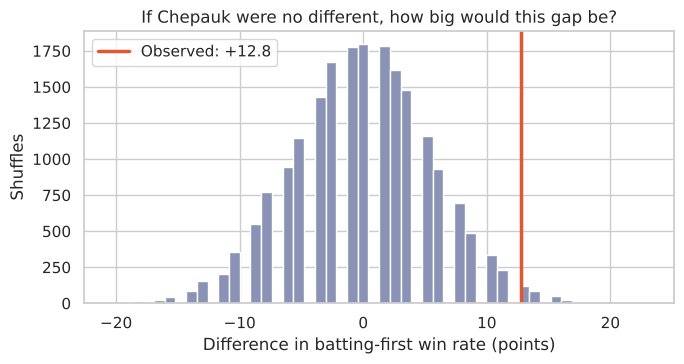

In [7]:
chep = decided[decided.chepauk]
other = decided[~decided.chepauk]
bf_chep = (~chep.chasing_team_won).astype(int).to_numpy()
bf_other = (~other.chasing_team_won).astype(int).to_numpy()

obs = bf_chep.mean() - bf_other.mean()
pooled = np.concatenate([bf_chep, bf_other])
perm = np.empty(20_000)
for i in range(len(perm)):
    s = rng.permutation(pooled)
    perm[i] = s[:len(bf_chep)].mean() - s[len(bf_chep):].mean()
p_perm = (np.sum(np.abs(perm) >= abs(obs)) + 1) / (len(perm) + 1)
ci = bootstrap_diff(bf_chep, bf_other)

print(f"Batting-first win rate: Chepauk {bf_chep.mean()*100:.1f}% (n={len(bf_chep)})  vs  elsewhere {bf_other.mean()*100:.1f}% (n={len(bf_other)})")
print(f"Difference = {obs*100:+.1f} points, bootstrap 95% CI {ci[0]*100:+.1f} to {ci[1]*100:+.1f}   permutation p = {p_perm:.3f}")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(perm * 100, bins=50, color=GREY)
ax.axvline(obs * 100, color=ORANGE, lw=2.5, label=f"Observed: {obs*100:+.1f}")
ax.set_xlabel("Difference in batting-first win rate (points)"); ax.set_ylabel("Shuffles")
ax.set_title("If Chepauk were no different, how big would this gap be?"); ax.legend()
plt.tight_layout(); plt.savefig("charts/07_chepauk_permutation.png", dpi=150); plt.show()

results.append(("Batting-first win rate: Chepauk minus elsewhere", "Permutation", f"{obs*100:+.1f} pts", f"{ci[0]*100:+.1f} to {ci[1]*100:+.1f}", p_perm))

### Test 5. Did scoring really jump in 2023 and 2024?

- **H0:** first-innings scores in 2023-24 come from the same distribution as 2008-2022.
- **Tests:** Mann-Whitney U (no normality assumption), a bootstrap CI for the difference in means, and
  Cohen's d as an effect size.

One confounder to flag: the **Impact Player rule** was introduced in 2023. It lets teams substitute a player
mid-match, which lengthens batting line-ups. This data cannot separate that rule from other changes (pitches,
player mix, attitude), so the jump is real in the data, but the cause is not established.

First-innings mean: 2008-2022 = 162.8 (n=931),  2023-2024 = 185.9 (n=143)
Difference = +23.1 runs, bootstrap 95% CI +17.0 to +29.1
Mann-Whitney p = 1.74e-13     Cohen's d = 0.75


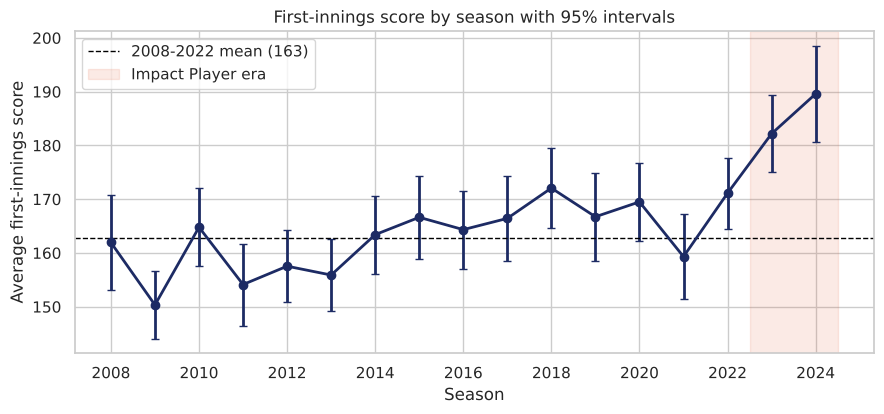

In [8]:
inn = balls.groupby(["match_id", "inning"]).total_runs.sum().reset_index()
first = inn[inn.inning == 1].merge(matches[["match_id", "season", "method"]], on="match_id")
first = first[first.method != "D/L"]          # rain-affected innings are not comparable

old = first[first.season <= 2022].total_runs.to_numpy()
new = first[first.season >= 2023].total_runs.to_numpy()

u, p_mw = stats.mannwhitneyu(new, old, alternative="two-sided")
diff = new.mean() - old.mean()
ci = bootstrap_diff(new, old)
pooled_sd = np.sqrt(((len(new)-1)*new.var(ddof=1) + (len(old)-1)*old.var(ddof=1)) / (len(new)+len(old)-2))
d = diff / pooled_sd

print(f"First-innings mean: 2008-2022 = {old.mean():.1f} (n={len(old)}),  2023-2024 = {new.mean():.1f} (n={len(new)})")
print(f"Difference = {diff:+.1f} runs, bootstrap 95% CI {ci[0]:+.1f} to {ci[1]:+.1f}")
print(f"Mann-Whitney p = {p_mw:.2e}     Cohen's d = {d:.2f}")

results.append(("First-innings score: 2023-24 minus 2008-22", "Mann-Whitney", f"{diff:+.1f} runs", f"{ci[0]:+.1f} to {ci[1]:+.1f}", p_mw))

# Is it a sudden break or a slow climb? Compare each season against the 2008-2022 baseline.
season_scores = first.groupby("season").total_runs.agg(["mean", "sem"])
fig, ax = plt.subplots(figsize=(9, 4.3))
ax.errorbar(season_scores.index, season_scores["mean"], yerr=1.96 * season_scores["sem"], fmt="o-", color=NAVY, capsize=3, lw=2)
ax.axhline(old.mean(), color="black", ls="--", lw=1, label=f"2008-2022 mean ({old.mean():.0f})")
ax.axvspan(2022.5, 2024.5, color=ORANGE, alpha=0.12, label="Impact Player era")
ax.set_xticks(range(2008, 2025, 2))
ax.set_xlabel("Season"); ax.set_ylabel("Average first-innings score")
ax.set_title("First-innings score by season with 95% intervals"); ax.legend()
plt.tight_layout(); plt.savefig("charts/08_scoring_jump_ci.png", dpi=150); plt.show()

### Summary of tests, with multiple-testing correction

Six tests were run, so a raw p-value of 0.04 is less impressive than it looks. The **Holm-Bonferroni**
correction controls the chance of any false positive across all of them.

In [9]:
def holm(pvals):
    """Holm-Bonferroni adjusted p-values."""
    p = np.asarray(pvals)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (len(p) - rank) * p[idx])
        adj[idx] = min(1.0, running)
    return adj

summary = pd.DataFrame(results, columns=["Claim", "Test", "Effect", "95% CI", "p (raw)"])
summary["p (Holm)"] = holm(summary["p (raw)"].to_numpy())
summary["Verdict"] = np.where(summary["p (Holm)"] < 0.05, "Real effect", "No clear evidence")
summary["p (raw)"] = summary["p (raw)"].map(lambda p: f"{p:.2g}")
summary["p (Holm)"] = summary["p (Holm)"].map(lambda p: f"{p:.2g}")
print(summary.to_string(index=False))

                                          Claim         Test     Effect         95% CI p (raw) p (Holm)           Verdict
            Toss winner wins the match (vs 50%)     Binomial      50.8%   47.9 to 53.8    0.61     0.61 No clear evidence
                     Chasing team wins (vs 50%)     Binomial      54.1%   51.2 to 57.1   0.007    0.028       Real effect
          CSK win rate: Chepauk minus elsewhere Fisher exact  +17.4 pts  +4.3 to +30.3   0.015    0.044       Real effect
      Any team wins at own home ground (vs 50%)     Binomial      56.5%   52.5 to 60.4  0.0015   0.0075       Real effect
Batting-first win rate: Chepauk minus elsewhere  Permutation  +12.8 pts  +1.7 to +23.8   0.023    0.047       Real effect
     First-innings score: 2023-24 minus 2008-22 Mann-Whitney +23.1 runs +17.0 to +29.1 1.7e-13    1e-12       Real effect


**What the tests say.**

- **Toss: no evidence of an effect.** 50.8% with an interval of 47.9% to 53.8%. The first notebook's reading
  holds up.
- **Chasing: a small real edge.** 54.1% (CI 51.2% to 57.1%). It is modest, and it has been stable over time.
- **Scoring jump: very strong.** About 23 more first-innings runs in 2023-24 (CI +17 to +29), a large effect
  (Cohen's d = 0.75). The cause is not established; the Impact Player rule is one candidate.
- **Home advantage exists league-wide** (56.5%, CI 52.5% to 60.4%).
- **CSK at Chepauk and the reversed batting-first pattern are real but fragile.** Both pass the correction
  only narrowly (Holm p of 0.044 and 0.047), and their intervals are wide (+4 to +30 points, and +2 to +24).
  CSK's 70.4% is also above the league-wide home rate of 56.5% (p = 0.02, not corrected), so Chepauk does look
  better than ordinary home advantage, but this is one franchise and 71 matches, and CSK is also a strong team
  overall, which this data cannot separate from the ground.

Absence of evidence is not evidence of absence: the toss result says "no effect detected", not "no effect".

## Part 2. Prediction: can we forecast the winner before the match?

**Setup**
- **Unit:** one decided match. Target = 1 if `team1` won. Which side is "team1" is randomised with a fixed
  seed, so the model cannot learn anything from the order the teams happen to be listed in.
- **Features** use only information known *before* the first ball: team strength rating, recent form, venue
  record, home advantage, and the toss.
- **Split:** train on 2008-2022, test on 2023-2024 (the future). A random split would let the model see
  matches from the same season it is being tested on, which overstates accuracy.
- **Baselines** the model must beat: a coin flip, "always back the team with the better record so far", and
  "always back the home team".

### Step 1. Team strength with an Elo rating

Elo is a simple rating system: every team starts at 1500, gains points for beating strong opponents and
loses points for losing to weak ones. It is updated *after* each match, so a match's rating only reflects
earlier matches. Ratings are partly reset toward the mean each season because squads change at auctions.

In [10]:
def run_elo(df, k=20, season_carry=0.75, base=1500.0):
    """Return pre-match Elo for team1 and team2, using only earlier matches."""
    ratings, last_season = {}, None
    e1, e2 = [], []
    for _, m in df.sort_values(["date", "match_id"]).iterrows():
        if last_season is not None and m.season != last_season:
            ratings = {t: base + season_carry * (r - base) for t, r in ratings.items()}
        last_season = m.season
        r1, r2 = ratings.get(m.team1, base), ratings.get(m.team2, base)
        e1.append(r1); e2.append(r2)
        if pd.notna(m.winner):
            exp1 = 1 / (1 + 10 ** ((r2 - r1) / 400))
            s1 = 1.0 if m.winner == m.team1 else 0.0
            ratings[m.team1] = r1 + k * (s1 - exp1)
            ratings[m.team2] = r2 + k * ((1 - s1) - (1 - exp1))
    out = df.sort_values(["date", "match_id"]).copy()
    out["elo1"], out["elo2"] = e1, e2
    return out

# Choose K using only 2008-2022 (never the test years): lower log-loss on 2016-2022 is better.
from sklearn.metrics import log_loss, accuracy_score, brier_score_loss

def elo_val_loss(k, carry):
    d = run_elo(matches, k=k, season_carry=carry)
    d = d[d.winner.notna() & d.season.between(2016, 2022)]
    p = 1 / (1 + 10 ** ((d.elo2 - d.elo1) / 400))
    return log_loss((d.winner == d.team1).astype(int), p)

grid = pd.DataFrame([(k, c, elo_val_loss(k, c)) for k in (5, 10, 20, 30) for c in (0.5, 0.75, 1.0)],
                    columns=["K", "season_carry", "val_logloss"]).sort_values("val_logloss")
print(grid.head(5).round(4).to_string(index=False))
best = grid.iloc[0]
K_BEST, CARRY_BEST = int(best.K), float(best.season_carry)
print(f"\nChosen: K = {K_BEST}, season_carry = {CARRY_BEST}   (a coin flip scores {np.log(2):.4f})")

 K  season_carry  val_logloss
 5          0.75       0.6934
 5          0.50       0.6937
10          0.50       0.6952
10          0.75       0.6955
 5          1.00       0.6969

Chosen: K = 5, season_carry = 0.75   (a coin flip scores 0.6931)


### Step 2. Build the feature table

Every feature below is computed from matches strictly *before* the one being predicted.

In [11]:
df = run_elo(matches, k=K_BEST, season_carry=CARRY_BEST)
df = df.sort_values(["date", "match_id"]).reset_index(drop=True)

# Randomise orientation: "a" and "b" replace team1 and team2 in a random order
flip = rng.random(len(df)) < 0.5
df["team_a"] = np.where(flip, df.team2, df.team1)
df["team_b"] = np.where(flip, df.team1, df.team2)
df["elo_a"] = np.where(flip, df.elo2, df.elo1)
df["elo_b"] = np.where(flip, df.elo1, df.elo2)

# Venue key, to merge spellings of the same ground ("Wankhede Stadium" and "Wankhede Stadium, Mumbai")
def venue_key(v):
    for key in ["Chidambaram", "Wankhede", "Eden Gardens", "Chinnaswamy", "Feroz Shah", "Arun Jaitley",
                "Rajiv Gandhi", "Sawai Mansingh", "Punjab Cricket", "Mohali", "Narendra Modi", "Motera",
                "Dubai", "Sharjah", "Zayed", "Brabourne", "DY Patil", "Maharashtra Cricket"]:
        if isinstance(v, str) and key in v:
            return {"Arun Jaitley": "Feroz Shah", "Motera": "Narendra Modi", "Mohali": "Punjab Cricket"}.get(key, key)
    return v
df["venue_k"] = df.venue.map(venue_key)

# Walk through matches in time order, keeping running records
form, hist = {}, {}              # recent results per team, and (n, wins_batting_first) per venue
cum = {}                          # team -> [wins, played]
feat = []
for _, m in df.iterrows():
    def recent(t):
        r = form.get(t, [])[-5:]
        return (sum(r) + 1.5) / (len(r) + 3)          # smoothed toward 0.5
    def career(t):
        w, p = cum.get(t, [0, 0]); return (w + 5) / (p + 10)
    vn, vw = hist.get(m.venue_k, (0, 0))
    bat_first_rate = (vw + 10 * 0.46) / (vn + 10)     # smoothed toward the league-wide rate
    feat.append({"form_a": recent(m.team_a), "form_b": recent(m.team_b),
                 "career_a": career(m.team_a), "career_b": career(m.team_b),
                 "venue_bat_first_rate": bat_first_rate, "venue_n": vn})
    if pd.notna(m.winner):
        for t in (m.team_a, m.team_b):
            form.setdefault(t, []).append(int(m.winner == t))
            c = cum.setdefault(t, [0, 0]); c[0] += int(m.winner == t); c[1] += 1
        bat_first = m.toss_winner if m.toss_decision == "bat" else (m.team_b if m.toss_winner == m.team_a else m.team_a)
        h = hist.get(m.venue_k, (0, 0))
        hist[m.venue_k] = (h[0] + 1, h[1] + int(m.winner == bat_first))
df = pd.concat([df, pd.DataFrame(feat)], axis=1)

df["home_a"] = [int(is_home(a, v)) for a, v in zip(df.team_a, df.venue)]
df["home_b"] = [int(is_home(b, v)) for b, v in zip(df.team_b, df.venue)]
df["toss_a"] = (df.toss_winner == df.team_a).astype(int)
df["field_first"] = (df.toss_decision == "field").astype(int)
df["a_bats_first"] = np.where(df.toss_a == 1, 1 - df.field_first, df.field_first)    # known after the toss
df["elo_diff"] = df.elo_a - df.elo_b
df["form_diff"] = df.form_a - df.form_b
df["career_diff"] = df.career_a - df.career_b
df["home_diff"] = df.home_a - df.home_b
df["bat_first_edge"] = (2 * df.a_bats_first - 1) * (df.venue_bat_first_rate - 0.5)   # venue favours the side batting first?
df["y"] = (df.winner == df.team_a).astype(int)

FEATURES = ["elo_diff", "form_diff", "career_diff", "home_diff", "toss_a", "bat_first_edge"]
data = df[df.winner.notna()].reset_index(drop=True)
train, test = data[data.season <= 2022], data[data.season >= 2023]
print(f"Train: {len(train)} matches (2008-2022)   Test: {len(test)} matches (2023-2024)")
print(f"Share where team A won: train {train.y.mean():.3f}, test {test.y.mean():.3f} (should be near 0.5 after randomising)")
data[FEATURES].describe().round(2).T[["mean", "std", "min", "max"]]

Train: 946 matches (2008-2022)   Test: 144 matches (2023-2024)
Share where team A won: train 0.499, test 0.486 (should be near 0.5 after randomising)


                mean    std    min    max
elo_diff       -0.69  17.31 -63.39  50.90
form_diff      -0.00   0.20  -0.50   0.62
career_diff    -0.00   0.09  -0.32   0.29
home_diff      -0.03   0.74  -1.00   1.00
toss_a          0.51   0.50   0.00   1.00
bat_first_edge -0.00   0.08  -0.23   0.21

### Step 3. Fit models and compare against baselines

Three models of increasing flexibility:
- **Elo only** (no fitting): the rating's own win probability.
- **Logistic regression** on all features, with standardisation. Simple, and its coefficients are readable.
- **Gradient boosting**, kept shallow and regularised because there are only about 1,000 training matches.

Metrics: accuracy (easy to read), **log-loss** and **Brier score** (reward honest probabilities; a coin flip
scores 0.693 and 0.250). With about 145 test matches the accuracy has a standard error near 4 points, so
bootstrap intervals are reported rather than a single number.

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def make_models():
    return {
        "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=1000)),
        "Gradient boosting": HistGradientBoostingClassifier(max_depth=2, learning_rate=0.05, max_iter=150,
                                                            l2_regularization=5.0, min_samples_leaf=30, random_state=SEED),
    }

def score(y, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return {"accuracy": accuracy_score(y, p > 0.5), "log_loss": log_loss(y, p), "brier": brier_score_loss(y, p)}

def predictions(train, test):
    """Return a dict of name -> predicted P(team A wins) for the test rows."""
    out = {}
    out["Coin flip"] = np.full(len(test), 0.5)
    # Baselines output a modest 55/45 probability so that log-loss compares them fairly with the models
    out["Better record so far"] = 0.5 + 0.05 * np.sign(test.career_diff.to_numpy())
    out["Back the home team"] = 0.5 + 0.05 * test.home_diff.to_numpy()
    out["Elo only"] = 1 / (1 + 10 ** (-test.elo_diff.to_numpy() / 400))
    for name, model in make_models().items():
        model.fit(train[FEATURES], train.y)
        out[name] = model.predict_proba(test[FEATURES])[:, 1]
    return out

preds = predictions(train, test)
rows = []
for name, p in preds.items():
    s = score(test.y, p)
    rows.append({"Model": name, **s})
table = pd.DataFrame(rows).set_index("Model")
print(table.round(3).to_string())

                      accuracy  log_loss  brier
Model                                          
Coin flip                0.514     0.693  0.250
Better record so far     0.569     0.684  0.246
Back the home team       0.507     0.694  0.251
Elo only                 0.521     0.694  0.250
Logistic regression      0.521     0.704  0.255
Gradient boosting        0.507     0.709  0.257


### Is the improvement over a coin flip real, given only ~145 test matches?

A bootstrap over test matches gives an interval for each model's accuracy, and for its *advantage* over the
coin-flip log-loss.

In [13]:
y_test = test.y.to_numpy()
B = 5000
idx = np.random.default_rng(SEED).integers(0, len(y_test), size=(B, len(y_test)))

def boot_ci(p, fn):
    vals = np.array([fn(y_test[i], p[i]) for i in idx])
    return np.percentile(vals, [2.5, 97.5])

ll_coin = lambda y, p: log_loss(y, np.full(len(y), 0.5))
boot_rows = []
for name in ["Better record so far", "Elo only", "Logistic regression", "Gradient boosting"]:
    p = preds[name]
    acc_lo, acc_hi = boot_ci(p, lambda y, q: accuracy_score(y, q > 0.5))
    gain = lambda y, q, p0=p: ll_coin(y, q) - log_loss(y, np.clip(q, 1e-6, 1 - 1e-6))
    g_lo, g_hi = boot_ci(p, gain)
    boot_rows.append({"Model": name, "Accuracy": f"{accuracy_score(y_test, p > 0.5)*100:.1f}%",
                 "Accuracy 95% CI": f"{acc_lo*100:.0f}% to {acc_hi*100:.0f}%",
                 "Log-loss gain vs coin": f"{ll_coin(y_test, p) - log_loss(y_test, p):+.3f}",
                 "Gain 95% CI": f"{g_lo:+.3f} to {g_hi:+.3f}"})
print(pd.DataFrame(boot_rows).to_string(index=False))

               Model Accuracy Accuracy 95% CI Log-loss gain vs coin      Gain 95% CI
Better record so far    56.9%      49% to 65%                +0.009 -0.008 to +0.024
            Elo only    52.1%      44% to 60%                -0.001 -0.008 to +0.006
 Logistic regression    52.1%      44% to 60%                -0.011 -0.035 to +0.012
   Gradient boosting    50.7%      42% to 59%                -0.015 -0.048 to +0.015


### Check robustness: walk-forward evaluation

One 2023-24 test set is a single draw. As a stability check, I repeat the exercise for every season from
2016 to 2024: train on all earlier seasons, test on that season. If a model's edge only appears in one
lucky year, this will expose it.

Pooled over 2016-2024 (9 test seasons, expanding training window):
                        n  log_loss  accuracy
model                                        
Coin flip             576     0.693     0.484
Better record so far  576     0.691     0.535
Elo only              576     0.693     0.524
Logistic regression   576     0.692     0.547
Gradient boosting     576     0.708     0.524


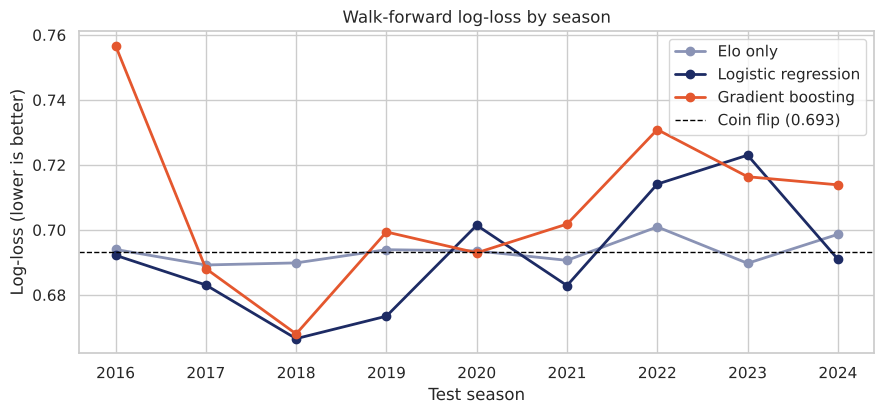

In [14]:
wf = []
for season in range(2016, 2025):
    tr, te = data[data.season < season], data[data.season == season]
    p = predictions(tr, te)
    for name in ["Coin flip", "Better record so far", "Elo only", "Logistic regression", "Gradient boosting"]:
        wf.append({"season": season, "model": name, "n": len(te), "correct": ((p[name] > 0.5) == te.y).sum(),
                   "log_loss": log_loss(te.y, np.clip(p[name], 1e-6, 1 - 1e-6))})
wf = pd.DataFrame(wf)
agg = wf.groupby("model").agg(n=("n", "sum"), correct=("correct", "sum"), log_loss=("log_loss", "mean"))
agg["accuracy"] = agg.correct / agg.n
agg = agg.drop(columns="correct").loc[["Coin flip", "Better record so far", "Elo only", "Logistic regression", "Gradient boosting"]]
print("Pooled over 2016-2024 (9 test seasons, expanding training window):")
print(agg.round(3).to_string())

pivot = wf.pivot(index="season", columns="model", values="log_loss")[["Elo only", "Logistic regression", "Gradient boosting"]]
fig, ax = plt.subplots(figsize=(9, 4.3))
for col, color in zip(pivot.columns, [GREY, NAVY, ORANGE]):
    ax.plot(pivot.index, pivot[col], marker="o", lw=2, label=col, color=color)
ax.axhline(np.log(2), color="black", ls="--", lw=1, label="Coin flip (0.693)")
ax.set_xlabel("Test season"); ax.set_ylabel("Log-loss (lower is better)")
ax.set_title("Walk-forward log-loss by season"); ax.legend()
plt.tight_layout(); plt.savefig("charts/09_walk_forward.png", dpi=150); plt.show()

### Are the probabilities honest? A calibration check

A model that says "70%" should be right about 70% of the time. Predictions from the walk-forward run are
pooled and grouped into bins to compare stated confidence with actual win rate.

              predicted  actual    n
bin                                 
(0.0, 0.35]       0.321   0.300   10
(0.35, 0.45]      0.412   0.512  121
(0.45, 0.55]      0.499   0.495  297
(0.55, 0.65]      0.585   0.585  142
(0.65, 1.0]       0.668   0.333    6


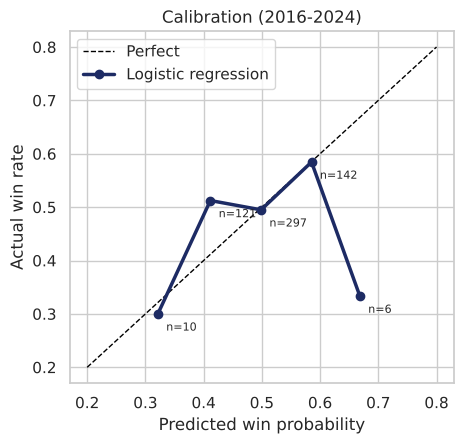

In [15]:
cal_rows = []
for season in range(2016, 2025):
    tr, te = data[data.season < season], data[data.season == season]
    p = predictions(tr, te)["Logistic regression"]
    cal_rows.append(pd.DataFrame({"p": p, "y": te.y.to_numpy()}))
cal = pd.concat(cal_rows)
cal["bin"] = pd.cut(cal.p, [0, 0.35, 0.45, 0.55, 0.65, 1.0])
curve = cal.groupby("bin", observed=True).agg(predicted=("p", "mean"), actual=("y", "mean"), n=("y", "size"))
print(curve.round(3).to_string())

fig, ax = plt.subplots(figsize=(4.8, 4.6))
ax.plot([0.2, 0.8], [0.2, 0.8], color="black", ls="--", lw=1, label="Perfect")
ax.plot(curve.predicted, curve.actual, marker="o", color=NAVY, lw=2.5, label="Logistic regression")
for _, r in curve.iterrows():
    ax.annotate(f"n={int(r.n)}", (r.predicted, r.actual), textcoords="offset points", xytext=(6, -12), fontsize=8)
ax.set_xlabel("Predicted win probability"); ax.set_ylabel("Actual win rate"); ax.set_title("Calibration (2016-2024)")
ax.legend(loc="upper left")
plt.tight_layout(); plt.savefig("charts/10_calibration.png", dpi=150); plt.show()

### What drives the predictions?

Two views. The logistic coefficients show direction and size on a standardised scale. **Permutation
importance** shuffles one feature at a time on the test set and measures how much log-loss gets worse, which
is a model-agnostic check that also works for gradient boosting.

home_diff         0.219
elo_diff          0.128
bat_first_edge    0.098
career_diff       0.054
toss_a            0.036
form_diff        -0.076


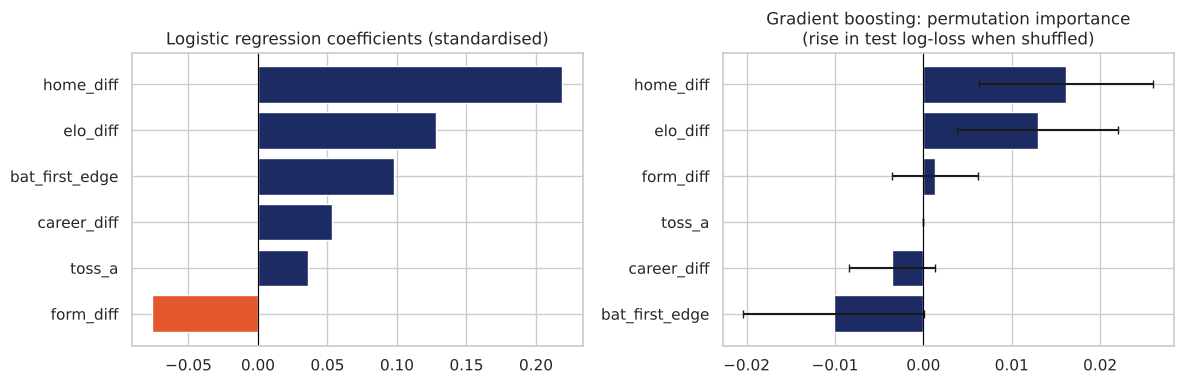

In [16]:
from sklearn.inspection import permutation_importance

lr = make_models()["Logistic regression"].fit(train[FEATURES], train.y)
coefs = pd.Series(lr[-1].coef_[0], index=FEATURES).sort_values()

gb = make_models()["Gradient boosting"].fit(train[FEATURES], train.y)
pi = permutation_importance(gb, test[FEATURES], test.y, scoring="neg_log_loss", n_repeats=50, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].barh(coefs.index, coefs.values, color=[ORANGE if v < 0 else NAVY for v in coefs.values])
ax[0].set_title("Logistic regression coefficients (standardised)"); ax[0].axvline(0, color="black", lw=0.8)
ax[1].barh(imp.index, imp.values, xerr=pi.importances_std[[FEATURES.index(f) for f in imp.index]], color=NAVY, capsize=3)
ax[1].set_title("Gradient boosting: permutation importance\n(rise in test log-loss when shuffled)"); ax[1].axvline(0, color="black", lw=0.8)
plt.tight_layout(); plt.savefig("charts/11_feature_importance.png", dpi=150); plt.show()
print(coefs.round(3).sort_values(ascending=False).to_string())

## Conclusions and limitations

**Main finding: pre-match information barely beats a coin flip in the IPL.** On the 2023-24 test set (144
matches) no model can be told apart from a coin. Accuracy is 51% to 52% for the fitted models, and the
interval on every log-loss gain over a coin flip includes zero. The simplest baseline, "back the team with
the better record so far", scored highest (56.9%), but its interval of 49% to 65% also includes 50%, and
over nine walk-forward seasons (2016-2024, 576 matches) it falls to 53.5%. In that walk-forward run logistic
regression reaches 54.7% accuracy with a log-loss of 0.692, a hair under the coin-flip 0.693.

Why this is plausible rather than a failure:
- **T20 is high-variance.** One over can swing a match, and teams are closely matched. The Elo ratings
  barely separate teams (the standard deviation of the pre-match rating gap is about 17 points, where a
  200-point gap means a 76% favourite).
- **Squads change every year** at the auction, so past results say less about the current team.
- **Home advantage is the one consistent signal.** It is the largest logistic coefficient, and agrees with
  the 56.5% found in Part 1.
- **More complex did not mean better.** Gradient boosting was worse than logistic regression on both
  evaluations, which is what you expect when roughly 1,000 noisy examples meet a flexible model.

**Limitations**
- About 145 test matches gives wide intervals, so small real edges cannot be confirmed or excluded.
- Ratings ignore who is actually playing. Squad strength, injuries, and overseas players are not in this data;
  adding them would be the next step.
- The Elo setting was chosen on 2016-2022 validation seasons, so the walk-forward folds for those years are
  slightly optimistic. The 2023-24 hold-out is untouched by that choice.
- The model sees the toss decision, which is known only at the toss, not before it.
- Team1/team2 order is randomised with a fixed seed, so every result here reproduces exactly.

## Export the results

The numbers above are saved to `results/results.json`. The interactive dashboard in `docs/` reads this file, so
its figures always come from this notebook rather than being typed in by hand. To refresh the dashboard after
re-running, run `python scripts/build_dashboard.py`.

In [17]:
import json, os
os.makedirs("results", exist_ok=True)
results_out = {
    "seed": SEED,
    "tests": summary[["Claim", "Test", "Effect", "95% CI", "p (Holm)", "Verdict"]].to_dict("records"),
    "models": table.reset_index().to_dict("records"),
    "boot": boot_rows,
    "wf_ll": {m: {int(r.season): round(float(r.log_loss), 4) for r in g.itertuples()} for m, g in wf.groupby("model")},
    "wf_pooled": agg.reset_index().to_dict("records"),
    "calibration": curve.reset_index(drop=True).round(4).to_dict("records"),
    "coefs": {k: round(float(v), 4) for k, v in coefs.items()},
}
with open("results/results.json", "w") as f:
    json.dump(results_out, f, indent=1, default=float)
print("Saved results/results.json")
print("Seed:", SEED)

Saved results/results.json
Seed: 42
